# 01 · EDA — Reseñas de apps bancarias del Ecuador
**Problema:** priorizar las reseñas negativas para que reciban atención.
**Target:** `es_negativa = 1` si `calificacion` ≤ 2, `0` en otro caso (clasificación binaria).
Ejecutar con *Restart* y luego *Run All*.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from src.datos import cargar_obt, cargar_obt_entrenamiento
sns.set_theme(style="whitegrid"); pd.set_option("display.width", 160)
df = cargar_obt_entrenamiento()
df["es_negativa"] = (df["calificacion"] <= 2).astype(int)
df["fecha_resena"] = pd.to_datetime(df["fecha_resena"])
import os
FIG = "/work/docs/figs/"; os.makedirs(FIG, exist_ok=True)

/usr/local/lib/python3.12/site-packages/snowflake/connector/connection/_connection.py:137: FutureWarning: enable_server_session_keep_alive_auto_detection was not set and defaults to True. In a future version, the default will change to None. Please provide an explicit value: True = check for running async queries before logout (queries are preserved); False/None = always send logout on close (async queries may be terminated by server). Logout behavior can also be overridden with server_session_keep_alive. See the connection parameter docs for more info.
  options = self.config.to_proto_options(


## 1. Tamaño, tipos y valores faltantes

In [2]:
print("Filas, columnas:", df.shape)
resumen = pd.DataFrame({"tipo": df.dtypes.astype(str), "nulos": df.isna().sum(), "% nulos": (df.isna().mean()*100).round(2), "únicos": df.nunique()})
resumen

Filas, columnas: (21698, 25)


,tipo,nulos,% nulos,únicos
review_id,str,0,0.00,21698
calificacion,int8,0,0.00,5
sentimiento_estrellas,str,0,0.00,3
me_gusta,int16,0,0.00,101
n_palabras,int8,0,0.00,99
es_comentario_corto,bool,0,0.00,2
es_solo_simbolos,bool,0,0.00,2
tiene_respuesta_banco,bool,0,0.00,2
respuesta_inconsistente,bool,0,0.00,2
horas_hasta_respuesta,float64,9120,42.03,1241


## 2. Estadística descriptiva

In [3]:
num = ["calificacion","me_gusta","n_palabras","horas_hasta_respuesta"]
display(df[num].describe(percentiles=[.01,.25,.5,.75,.95,.99]).T.round(2))
display(df[["banco","sentimiento_estrellas","es_comentario_corto","es_solo_simbolos","tiene_respuesta_banco","version_app_desconocida"]].astype(str).describe().T)

,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
calificacion,21698.0,3.15,1.88,1.0,1.0,1.0,4.0,5.0,5.0,5.00,5.0
me_gusta,21698.0,1.06,7.30,0.0,0.0,0.0,0.0,0.0,3.0,22.00,327.0
n_palabras,21698.0,12.60,15.81,1.0,1.0,2.0,6.0,18.0,45.0,76.03,100.0
horas_hasta_respuesta,12578.0,192.35,472.49,0.0,0.0,2.0,42.0,160.0,821.0,2635.23,4338.0


,count,unique,top,freq
banco,21698,8,Banco Pichincha,3009
sentimiento_estrellas,21698,3,positivo,11238
es_comentario_corto,21698,2,False,14258
es_solo_simbolos,21698,2,False,21369
tiene_respuesta_banco,21698,2,True,12951
version_app_desconocida,21698,2,False,18996


## 3. Distribución del target y desbalance

es_negativa
no negativa    55.8
negativa       44.2

Razón de desbalance (mayoritaria/minoritaria): 1.26


,n,pct_negativa,fecha_min,fecha_max
banco,,,,
Banco Guayaquil,3001,21.5,2026-02-16 16:42:48,2026-11-12 00:08:48
Banco Bolivariano,3000,26.4,2023-03-06 18:47:36,2026-11-11 17:41:45
Banco Pichincha,3009,32.6,2026-08-13 04:46:20,2026-11-12 01:11:20
Cooperativa JEP,3000,37.9,2018-04-20 03:40:02,2026-11-10 18:06:16
Produbanco,3000,52.5,2022-11-24 20:19:19,2026-11-11 17:45:28
Diners Club (blu),2490,59.9,2025-08-25 15:11:38,2026-11-10 21:07:11
Banco del Austro,1198,60.9,2019-12-23 15:53:03,2026-11-12 00:15:15
Banco del Pacífico,3000,74.6,2022-05-05 00:21:47,2026-11-02 20:05:36


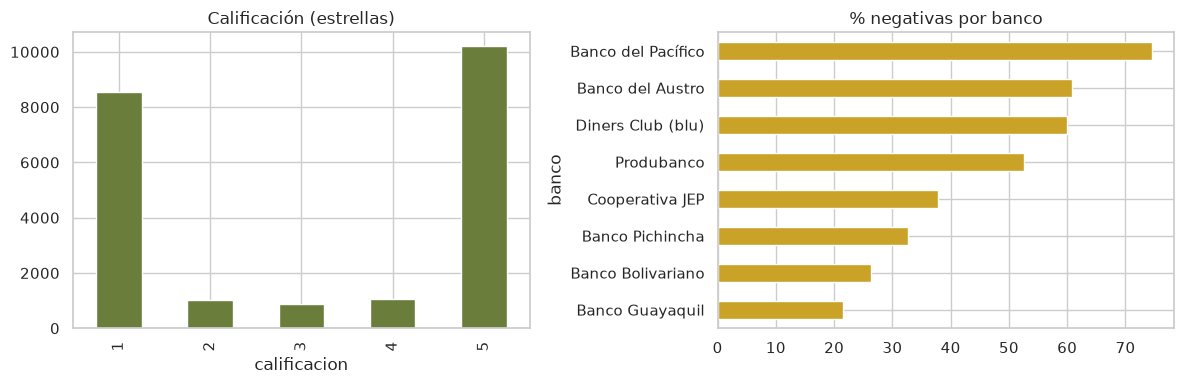

In [4]:
pct = df["es_negativa"].value_counts(normalize=True).rename({0:"no negativa",1:"negativa"})*100
print(pct.round(2).to_string())
print("\nRazón de desbalance (mayoritaria/minoritaria): %.2f" % (pct.max()/pct.min()))
tb = df.groupby("banco").agg(n=("es_negativa","size"), pct_negativa=("es_negativa","mean"), fecha_min=("fecha_resena","min"), fecha_max=("fecha_resena","max"))
tb["pct_negativa"] = (tb["pct_negativa"]*100).round(1)
display(tb.sort_values("pct_negativa"))
fig, ax = plt.subplots(1,2, figsize=(12,4))
df["calificacion"].value_counts().sort_index().plot.bar(ax=ax[0], color="#6b7d3a"); ax[0].set_title("Calificación (estrellas)")
tb["pct_negativa"].sort_values().plot.barh(ax=ax[1], color="#c9a227"); ax[1].set_title("% negativas por banco")
plt.tight_layout(); plt.savefig(FIG+"eda_target.png", dpi=150); plt.show()

## 4. Valores atípicos: IQR (boxplot) y Z-score ≥ 3

,variable,límite_sup_IQR,% fuera IQR,% |Z|≥3,máximo,mediana
0,n_palabras,42.0,5.87,2.14,100.0,6.0
1,me_gusta,0.0,16.43,0.97,327.0,0.0
2,horas_hasta_respuesta,397.0,10.92,2.66,4338.0,42.0


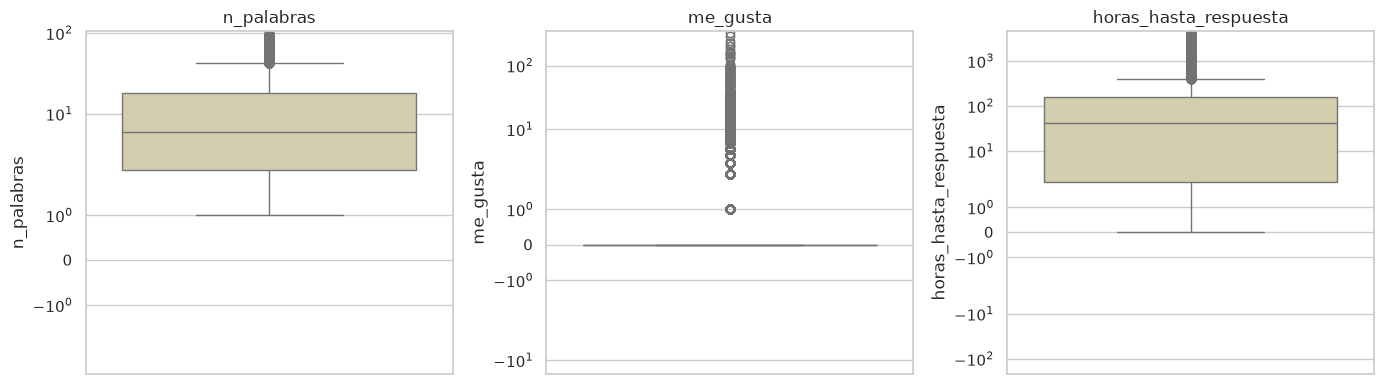

In [5]:
cols = ["n_palabras","me_gusta","horas_hasta_respuesta"]
filas=[]
for c in cols:
    s = df[c].dropna()
    q1,q3 = s.quantile([.25,.75]); iqr=q3-q1
    lim = q3+1.5*iqr
    z = np.abs(stats.zscore(s))
    filas.append({"variable":c,"límite_sup_IQR":round(lim,1),"% fuera IQR":round((s>lim).mean()*100,2),"% |Z|≥3":round((z>=3).mean()*100,2),"máximo":s.max(),"mediana":s.median()})
display(pd.DataFrame(filas))
fig, ax = plt.subplots(1,3, figsize=(14,4))
for a,c in zip(ax,cols):
    sns.boxplot(y=df[c].dropna(), ax=a, color="#d9d4a8"); a.set_yscale("symlog"); a.set_title(c)
plt.tight_layout(); plt.savefig(FIG+"eda_boxplots.png", dpi=150); plt.show()

## 5. Relación entre el target y las características
Se usa **Spearman** (las variables son asimétricas y con colas largas, y el target es binario). Se excluyen `calificacion` y `sentimiento_estrellas` porque definen el target.

es_comentario_corto       -0.477
anio                      -0.067
mes                       -0.054
es_solo_simbolos          -0.040
dia_semana_iso             0.013
version_app_desconocida    0.093
tiene_respuesta_banco      0.214
me_gusta                   0.232
n_palabras                 0.564


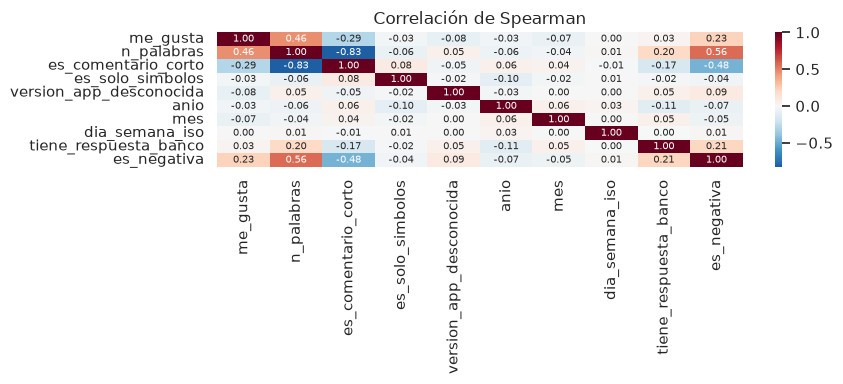

In [6]:
X = df[["me_gusta","n_palabras","es_comentario_corto","es_solo_simbolos","version_app_desconocida","anio","mes","dia_semana_iso"]].astype(float)
X["tiene_respuesta_banco"] = df["tiene_respuesta_banco"].astype(float)
cor = X.apply(lambda s: stats.spearmanr(s, df["es_negativa"])[0]).sort_values()
print(cor.round(3).to_string())
plt.figure(figsize=(9,4)); sns.heatmap(pd.concat([X, df["es_negativa"]],axis=1).corr(method="spearman"), cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size":7})
plt.title("Correlación de Spearman"); plt.tight_layout(); plt.savefig(FIG+"eda_correlacion.png", dpi=150); plt.show()

## 6. Hallazgos que cambian el modelado

H1 corto vs largo:
                       mean   size
es_comentario_corto              
False                0.613  14258
True                 0.114   7440 

H2 % negativa por longitud:
 bins_pal
(-1, 2]       0.114
(2, 5]        0.312
(5, 10]       0.528
(10, 20]      0.699
(20, 1000]    0.803
Name: es_negativa, dtype: float64 

H3 rango de fechas por banco:
                              fecha_min           fecha_max
banco                                                     
Banco Bolivariano  2023-03-06 18:47:36 2026-11-11 17:41:45
Banco Guayaquil    2026-02-16 16:42:48 2026-11-12 00:08:48
Banco Pichincha    2026-08-13 04:46:20 2026-11-12 01:11:20
Banco del Austro   2019-12-23 15:53:03 2026-11-12 00:15:15
Banco del Pacífico 2022-05-05 00:21:47 2026-11-02 20:05:36
Cooperativa JEP    2018-04-20 03:40:02 2026-11-10 18:06:16
Diners Club (blu)  2025-08-25 15:11:38 2026-11-10 21:07:11
Produbanco         2022-11-24 20:19:19 2026-11-11 17:45:28 

H4 % negativa por mes:
            mean  size

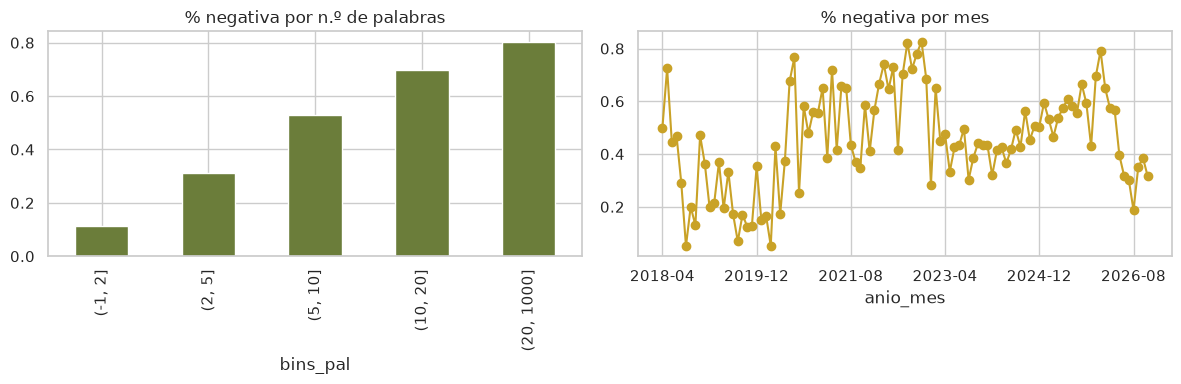

In [7]:
# H1: comentarios muy cortos
corto = df.groupby("es_comentario_corto")["es_negativa"].agg(["mean","size"]); print("H1 corto vs largo:\n", corto.round(3), "\n")
# H2: longitud vs negatividad
df["bins_pal"] = pd.cut(df["n_palabras"], [-1,2,5,10,20,1000])
print("H2 % negativa por longitud:\n", df.groupby("bins_pal", observed=True)["es_negativa"].mean().round(3), "\n")
# H3: ventana temporal distinta por banco
print("H3 rango de fechas por banco:\n", tb[["fecha_min","fecha_max"]], "\n")
# H4: deriva temporal del target
mes = df.groupby("anio_mes")["es_negativa"].agg(["mean","size"]); print("H4 % negativa por mes:\n", mes.round(3), "\n")
# H5: respuesta del banco (posterior a la reseña)
print("H5 % negativa según tiene_respuesta_banco:\n", df.groupby("tiene_respuesta_banco")["es_negativa"].mean().round(3), "\n")
# H6: versión desconocida
print("H6 % negativa según versión desconocida:\n", df.groupby("version_app_desconocida")["es_negativa"].mean().round(3))
fig, ax = plt.subplots(1,2, figsize=(12,4))
df.groupby("bins_pal", observed=True)["es_negativa"].mean().plot.bar(ax=ax[0], color="#6b7d3a"); ax[0].set_title("% negativa por n.º de palabras")
mes["mean"].plot(ax=ax[1], marker="o", color="#c9a227"); ax[1].set_title("% negativa por mes")
plt.tight_layout(); plt.savefig(FIG+"eda_hallazgos.png", dpi=150); plt.show()

### Tabla de hallazgos
| # | Hallazgo | Evidencia | Consecuencia en el modelo |
|---|---|---|---|
| 1 | El banco explica gran parte del target y las ventanas de fechas difieren | % negativa por banco: 21.5% (Guayaquil) a 74.6% (Pacífico); Pichincha cubre 3 meses y Austro desde 2019 | Hold-out y CV temporales; reportar el rendimiento por banco; vigilar cambio de prevalencia entre train y test |
| 2 | La longitud del comentario es la señal más fuerte | Spearman n_palabras vs target = 0.56; % negativa sube de 11.4% (≤2 palabras) a 80.3% (>20); 34% de comentarios cortos | Feature `log_n_palabras`; TF-IDF con 1–2 gramas; los cortos son difíciles de clasificar |
| 3 | Dos variables parecen predictivas pero ocurren después de la reseña | `tiene_respuesta_banco`: 52.9% negativas con respuesta vs 31.3% sin respuesta (Spearman 0.21); `me_gusta` Spearman 0.23 | Se excluyen (fuga): no existen al momento de predecir |
| 4 | Colas largas | n_palabras: 5.9% fuera de IQR, 2.1% con \|Z\|≥3 (máx. 100); me_gusta: 16.4% > 0, máx. 327; horas_hasta_respuesta máx. 4,338 | `log1p` en n_palabras; no se eliminan atípicos (las reseñas largas son legítimas y 80% negativas) |
| 5 | Versión de app desconocida se asocia a más negativas | 56.5% vs 42.5% | Se conserva `version_app_desconocida` como binaria |
| 6 | Desbalance leve | 44.2% negativas, razón 1.26 | PR-AUC como métrica; `class_weight` opcional; sin remuestreo |